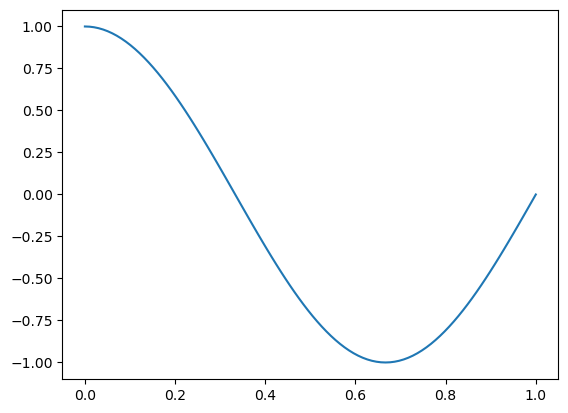

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def true_fun(X):
    return np.cos(1.5 * np.pi * X)
plt.plot(np.linspace(0, 1, 100), true_fun(np.linspace(0, 1, 100)))
plt.show()

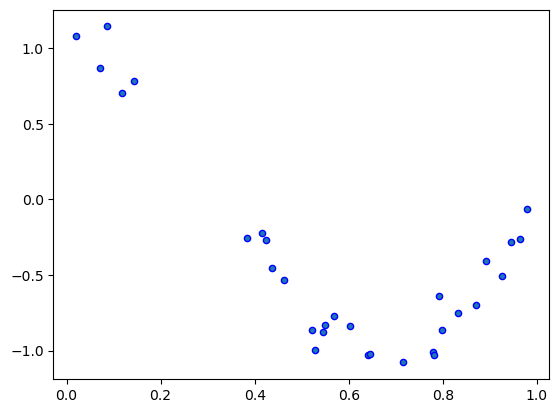

In [2]:
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1
plt.scatter(X, y, edgecolor='b', s=20)
plt.show()

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

X_vis = np.linspace(0, 1, 100)

**3. Como primera actividad de la tarea deberás dividir el conjunto de datos en subconjuntos de entrenamiento y prueba, utilizando la función train_test_split de sklearn, con una proporción adecuada para cada uno, dado el tamaño del conjunto de datos.**

In [4]:
#Usamos la proporción recomendada de 2/3 para entrenar y 1/3 para testear
test_size=0.33
X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1,1), y, test_size=test_size)




**4. Entrena modelos de regresión lineal sobre el conjunto de entrenamiento generado, utilizando PolynomialFeatures con grados entre 1 y 30, para transformar las características de entrada de cada modelo y así modificar la complejidad de estos.**



In [5]:
##Usando la forma rápida de hacer esto del curso visualización de datos, importamos pipeline
from sklearn.pipeline import Pipeline

pipe_poly = {}
for grados in range(1,31):
  pipe_poly[grados] = Pipeline([
      ("poly", PolynomialFeatures(degree=grados, include_bias=False)),
      ("lineal", LinearRegression())
  ])
  pipe_poly[grados].fit(X_train, y_train)




**5. Utilizando el conjunto de prueba, busca dentro de los modelos entrenados uno que presente subajuste, otro con sobreajuste y finalmente uno con ajuste adecuado. Identifique claramente cuál fue el grado utilizado por PolynomialFeatures para cada uno.**

In [6]:
from sklearn.metrics import mean_squared_error
import pandas as pd

ajuste = []

for grado in range(1,31):
  modelo= pipe_poly[grado]

  y_pred_train= modelo.predict(X_train)
  y_pred_test = modelo.predict(X_test)

  error_train= mean_squared_error(y_train, y_pred_train)
  error_test= mean_squared_error(y_test, y_pred_test)

  ajuste.append([grado, error_train, error_test])

errores = pd.DataFrame(ajuste, columns=["grado", "error_train", "error_test"]).set_index("grado")
errores["brecha"]=errores["error_test"]- errores["error_train"]
print(errores)

sobreajuste=errores["brecha"].idxmax()
print("Sobre Ajuste:", sobreajuste)

grado_ajuste=errores["error_test"].idxmin()
print("Grado de ajuste:", grado_ajuste)

grado_subajuste=errores["error_train"].idxmax()
print("Grado de Subajuste:",grado_subajuste)

        error_train  error_test      brecha
grado                                      
1      2.555867e-01    0.206561   -0.049026
2      2.672782e-02    0.038814    0.012086
3      1.221475e-02    0.014148    0.001933
4      1.089882e-02    0.015041    0.004143
5      1.053662e-02    0.014160    0.003624
6      1.042627e-02    0.014301    0.003874
7      7.935659e-03    0.028940    0.021004
8      7.932362e-03    0.028939    0.021007
9      7.725258e-03    0.028170    0.020445
10     6.894982e-03    0.046976    0.040081
11     6.720531e-03    0.055494    0.048774
12     5.907035e-03    0.074511    0.068604
13     2.669695e-03    0.181402    0.178732
14     2.332926e-03    0.399100    0.396767
15     1.859255e-03    0.179602    0.177742
16     1.819386e-03    2.419875    2.418056
17     1.797910e-03    1.469829    1.468031
18     7.741108e-04  773.581268  773.580494
19     6.190647e-04  335.994746  335.994127
20     4.891922e-04  143.530293  143.529804
21     4.667681e-05  718.697875 

**6. Grafica de manera separada para cada modelo, las predicciones que realiza sobre el conjunto de datos X_vis, el cual se encuentra definido en la tercera celda. Compare visualmente estas predicciones con la forma de la función sinusoidal original y comente los resultados.**

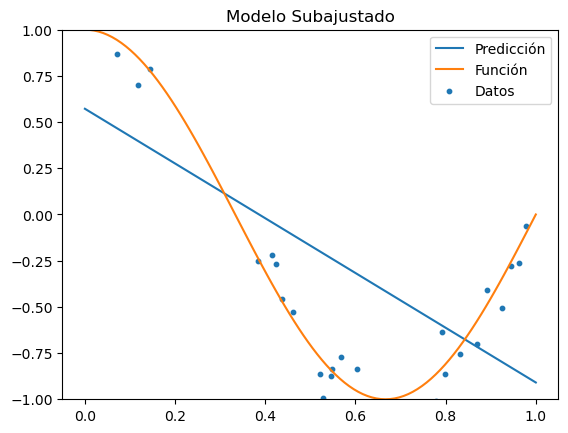

In [7]:
##Tenemos los 3 códigos para cada una de las curvas
#Modelo subajustado
plt.figure()
plt.plot(X_vis, pipe_poly[grado_subajuste].predict(X_vis.reshape(-1,1)), label="Predicción")
plt.plot(X_vis, true_fun(X_vis), label="Función")
plt.scatter(X,y, s=10, label="Datos")
plt.ylim(-1,1)
plt.title(f"Modelo Subajustado")
plt.legend()
plt.show()

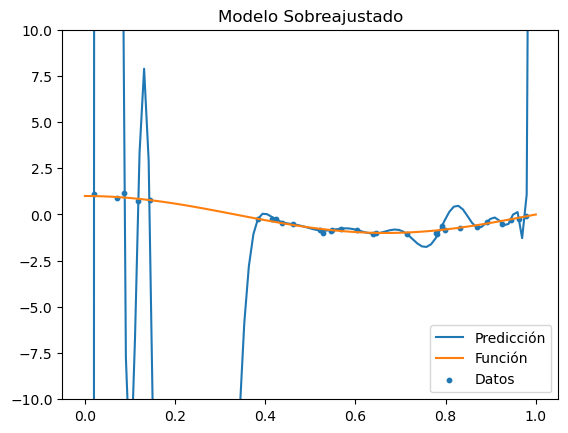

In [8]:
#Modelo sobreajustado
plt.figure()
plt.plot(X_vis, pipe_poly[sobreajuste].predict(X_vis.reshape(-1,1)), label="Predicción")
plt.plot(X_vis, true_fun(X_vis), label="Función")
plt.scatter(X,y, s=10, label="Datos")
plt.ylim(-10,10)
plt.title(f"Modelo Sobreajustado")
plt.legend()
plt.show()

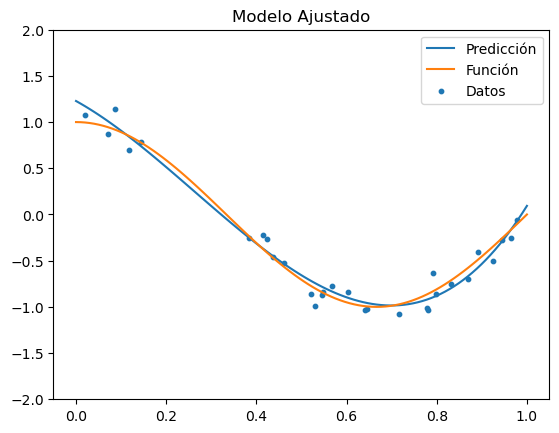

In [9]:
#Modelo ajustado
plt.figure()
plt.plot(X_vis, pipe_poly[grado_ajuste].predict(X_vis.reshape(-1,1)), label="Predicción")
plt.plot(X_vis, true_fun(X_vis), label="Función")
plt.scatter(X,y, s=10, label="Datos")
plt.ylim(-2,2)
plt.title(f"Modelo Ajustado")
plt.legend()
plt.show()

**Comentarios finales**

**En conclusión, partimos de un modelo donde usamos 1/3 de los datos para entrenar el modelo y 2/3 para testear, donde vemos que el modelo con mayor subajuste corresponde a aquel en el que se utiliza un grado, mientras que el de mayor sobreajuste es aquel con 17 grados, mientras que el modelo óptimo, que se obtiene al buscar el argumento que minimice los errores en el test de pruebas nos entrega que lo óptimo corresponden a 7 grados.**

**Lo anterior, concuerda con lo observado visualmente, donde el modelo subajustado muestra una representación lineal de los datos dado su simplicidad, mientras que el sobreajustado presenta múltiples puntos que no se ubican sobre la función, yendo incluso más allá de los bordes establecidos para visualizarlo de forma gráfica. Por su lado, vemos como el modelo ajustado sigue la tendencia de la función, presentando pequeñas desviaciones de esta tendencia**